# TimesNet: Temporal 2D-Variation Modeling for General Time Series Analysis

**Paper**: Haixu Wu, Tengge Hu, Yong Liu, Hang Zhou, Jianmin Wang, Mingsheng Long. *TimesNet: Temporal 2D-Variation Modeling for General Time Series Analysis*. **ICLR 2023**. [arXiv:2210.02186](https://arxiv.org/abs/2210.02186)

**Official code**: [github.com/thuml/Time-Series-Library](https://github.com/thuml/Time-Series-Library) (`models/TimesNet.py`, `layers/Conv_Blocks.py`, `layers/Embed.py`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/timesnet_2d_variation.ipynb)

**Key ideas**:
- **Multi-periodicity**: real series mix several periods (daily, weekly, ...). TimesNet finds the top-$k$ periods with an **FFT** of the (embedded) input.
- **1D → 2D**: for each period $p$ the length-$T$ series is folded into a $\lceil T/p\rceil \times p$ image. Columns hold **intraperiod** variation (neighbouring time steps), rows hold **interperiod** variation (the same phase in consecutive periods).
- **2D kernels**: a parameter-efficient **Inception block** (multi-scale 2D convs) captures both variations at once; the image is then unfolded back to 1D.
- **Adaptive aggregation**: the $k$ period-specific outputs are fused with softmax weights given by the FFT amplitudes of their frequencies.
- Stacked **TimesBlocks** with residual connections; forecasting by a linear "align" layer that extends the length-$L$ embedding to $L+H$ before the blocks.

This notebook re-implements TimesNet from scratch in PyTorch, following the official TSLib code line by line, and trains it with the TSLib script `scripts/long_term_forecast/ETT_script/TimesNet_ETTh1.sh` (ETTh1, 96 → 96).

## Setup

Everything needed (PyTorch, NumPy, pandas, scikit-learn, matplotlib) is preinstalled on Colab, so there is no `%pip install` step.

In [1]:
import os, time, json, math, random
import numpy as np, pandas as pd, torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

torch 2.12.1+cu130 | device: cuda | NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition


## Data: ETTh1 (standard benchmark split)

ETTh1 = hourly electricity-transformer data, 7 channels (`HUFL, HULL, MUFL, MULL, LUFL, LULL, OT`).
We use the standard Informer/Autoformer/TSLib borders: 12 months train, 4 months val, 4 months test, a
`StandardScaler` fitted on the train rows only, and metrics on the scaled data (what papers report).

The official code also feeds **calendar features** (`--embed timeF`, `--freq h`): hour-of-day, day-of-week,
day-of-month and day-of-year, each scaled to $[-0.5, 0.5]$. We compute them with the same borders and return
them from a small extension of the shared `WindowDataset` (the helper itself is unchanged).

In [2]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

# --- extension: calendar features ("timeF", freq='h') with the same borders ---
def load_etth1_marks(lookback):
    d = pd.to_datetime(pd.read_csv(URL)["date"])
    marks = np.stack([d.dt.hour / 23.0 - 0.5,             # HourOfDay
                      d.dt.dayofweek / 6.0 - 0.5,         # DayOfWeek
                      (d.dt.day - 1) / 30.0 - 0.5,        # DayOfMonth
                      (d.dt.dayofyear - 1) / 365.0 - 0.5  # DayOfYear
                     ], 1).astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    return (marks[:n_tr], marks[n_tr - lookback: n_tr + n_va],
            marks[n_tr + n_va - lookback: n_tr + n_va + n_te])

class WindowDatasetMark(WindowDataset):
    """Same windows as WindowDataset, plus the calendar features of input and target steps."""
    def __init__(self, arr, marks, L, H, stride=1):
        super().__init__(arr, L, H, stride); self.marks = marks
    def __getitem__(self, k):
        x, y = super().__getitem__(k); i = self.idx[k]
        return (x, y, torch.from_numpy(self.marks[i:i+self.L]),
                torch.from_numpy(self.marks[i+self.L:i+self.L+self.H]))

L, H = 96, 96
train, val, test, cols = load_etth1(L)
m_train, m_val, m_test = load_etth1_marks(L)
train_ds = WindowDatasetMark(train, m_train, L, H)
val_ds   = WindowDatasetMark(val,   m_val,   L, H)
test_ds  = WindowDatasetMark(test,  m_test,  L, H)
print("channels:", cols)
print(f"windows  train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
windows  train=8449  val=2785  test=2785


## Configuration (TSLib `TimesNet_ETTh1.sh`, `ETTh1_96_96`)

| arg | value | arg | value |
|---|---|---|---|
| `seq_len` | 96 | `pred_len` | 96 |
| `e_layers` | 2 | `top_k` | 5 |
| `d_model` | 16 | `d_ff` | 32 |
| `num_kernels` | 6 (default) | `dropout` | 0.1 (default) |
| `embed` | `timeF`, freq `h` | `loss` | MSE |
| `learning_rate` | 1e-4 (Adam) | `lradj` | `type1` (halve every epoch) |
| `batch_size` | 32 | `train_epochs` / `patience` | 10 / 3 |

(`label_len`, `d_layers`, `factor`, `dec_in` from the script are unused by TimesNet.)

In [3]:
class Config:
    seq_len, pred_len = L, H
    enc_in = c_out = 7
    e_layers = 2
    d_model, d_ff = 16, 32
    top_k = 5
    num_kernels = 6
    dropout = 0.1
    learning_rate = 1e-4
    batch_size = 32
    train_epochs, patience = 10, 3
cfg = Config()

## Component 1: Data embedding

As in TSLib's `DataEmbedding`: the value embedding is a 1D conv (kernel 3, circular padding, no bias) across the 7 channels, plus a fixed sinusoidal **positional** embedding, plus a linear projection of the 4 calendar features (`timeF`):

$$X^0_{\text{emb}} = \mathrm{Dropout}\big(\mathrm{Conv1d}(X) + \mathrm{PE} + W_t\, X_{\text{mark}}\big) \in \mathbb{R}^{L\times d_{\text{model}}}$$

The input is first normalised per window (instance norm from Non-stationary Transformer) and de-normalised at the output.

In [4]:
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).float().unsqueeze(1)
        div = (torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)).exp()
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return self.pe[:, :x.size(1)]

class TokenEmbedding(nn.Module):
    def __init__(self, c_in, d_model):
        super().__init__()
        self.tokenConv = nn.Conv1d(c_in, d_model, kernel_size=3, padding=1,
                                   padding_mode="circular", bias=False)
        nn.init.kaiming_normal_(self.tokenConv.weight, mode="fan_in", nonlinearity="leaky_relu")
    def forward(self, x):                       # [B,T,C] -> [B,T,d_model]
        return self.tokenConv(x.permute(0, 2, 1)).transpose(1, 2)

class TimeFeatureEmbedding(nn.Module):
    def __init__(self, d_model, d_inp=4):       # freq 'h' -> 4 calendar features
        super().__init__()
        self.embed = nn.Linear(d_inp, d_model, bias=False)
    def forward(self, x):
        return self.embed(x)

class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, dropout=0.1):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in, d_model)
        self.position_embedding = PositionalEmbedding(d_model)
        self.temporal_embedding = TimeFeatureEmbedding(d_model)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, x_mark):
        if x_mark is None:
            x = self.value_embedding(x) + self.position_embedding(x)
        else:
            x = self.value_embedding(x) + self.temporal_embedding(x_mark) + self.position_embedding(x)
        return self.dropout(x)

## Component 2: FFT period discovery

For an embedded series $X \in \mathbb{R}^{T\times d}$:

$$A = \mathrm{Avg}\big(\mathrm{Amp}(\mathrm{FFT}(X))\big),\quad \{f_1,\dots,f_k\} = \operatorname*{arg\,Topk}_{f \in \{1,\dots,\lfloor T/2\rfloor\}} A_f,\quad p_i = \left\lfloor \frac{T}{f_i}\right\rfloor$$

The amplitude is averaged over the batch **and** the channels to choose the frequencies (so the whole batch shares
the same periods), the DC term $f=0$ is excluded, and the per-sample amplitudes $A_{f_i}$ (averaged over channels only)
are kept as the aggregation weights.

In [5]:
def FFT_for_Period(x, k=2):
    # x: [B, T, C]
    xf = torch.fft.rfft(x, dim=1)
    frequency_list = abs(xf).mean(0).mean(-1)   # amplitude per frequency, averaged over batch & channels
    frequency_list[0] = 0                       # drop the DC component
    _, top_list = torch.topk(frequency_list, k)
    top_list = top_list.detach().cpu().numpy()
    period = x.shape[1] // top_list
    return period, abs(xf).mean(-1)[:, top_list]  # periods [k], per-sample weights [B, k]

# Quick look: which periods does the raw OT channel of the training set contain?
seg = torch.from_numpy(train[None, :L + H, :])
p, w = FFT_for_Period(seg, k=5)
print("top-5 periods on the first 192 training steps (raw data):", p.tolist())

top-5 periods on the first 192 training steps (raw data): [192, 96, 64, 21, 48]


## Component 3: Inception block (2D kernels)

`Inception_Block_V1` runs `num_kernels` parallel `Conv2d`s with square kernels $1\times1, 3\times3, \dots, (2n-1)\times(2n-1)$
("same" padding) and averages their outputs. Each TimesBlock uses the parameter-efficient pair
`Inception(d_model→d_ff) → GELU → Inception(d_ff→d_model)`, **shared across all $k$ periods**.
Weights use Kaiming-normal init (fan-out) and zero bias, as in TSLib.

In [6]:
class Inception_Block_V1(nn.Module):
    def __init__(self, in_channels, out_channels, num_kernels=6, init_weight=True):
        super().__init__()
        self.num_kernels = num_kernels
        self.kernels = nn.ModuleList([nn.Conv2d(in_channels, out_channels, kernel_size=2 * i + 1, padding=i)
                                      for i in range(num_kernels)])
        if init_weight:
            for m in self.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                    if m.bias is not None:
                        nn.init.constant_(m.bias, 0)
    def forward(self, x):
        return torch.stack([k(x) for k in self.kernels], dim=-1).mean(-1)

## Component 4: TimesBlock = 1D→2D reshape + 2D conv + adaptive aggregation

For each period $p_i$ (with $f_i = \lceil T/p_i\rceil$ rows after zero-padding $T$ up to a multiple of $p_i$):

$$X^{i}_{2D} = \mathrm{Reshape}_{f_i\times p_i}\big(\mathrm{Padding}(X)\big),\qquad
\hat X^{i}_{2D} = \mathrm{Inception}(X^{i}_{2D}),\qquad
\hat X^{i}_{1D} = \mathrm{Trunc}_T\big(\mathrm{Reshape}_{1\times(f_i p_i)}(\hat X^{i}_{2D})\big)$$

$$\hat A_{f_1},\dots,\hat A_{f_k} = \mathrm{Softmax}(A_{f_1},\dots,A_{f_k}),\qquad
X^{l} = X^{l-1} + \sum_{i=1}^{k} \hat A_{f_i}\, \hat X^{i}_{1D}$$

Here $T = L + H = 192$ because the forecasting head first extends the embedding to the full length (see next cell).

In [7]:
class TimesBlock(nn.Module):
    def __init__(self, configs):
        super().__init__()
        self.seq_len, self.pred_len, self.k = configs.seq_len, configs.pred_len, configs.top_k
        self.conv = nn.Sequential(
            Inception_Block_V1(configs.d_model, configs.d_ff, num_kernels=configs.num_kernels),
            nn.GELU(),
            Inception_Block_V1(configs.d_ff, configs.d_model, num_kernels=configs.num_kernels))

    def forward(self, x):
        B, T, N = x.size()
        period_list, period_weight = FFT_for_Period(x, self.k)
        total = self.seq_len + self.pred_len
        res = []
        for i in range(self.k):
            period = period_list[i]
            # zero-pad so the length is a multiple of the period
            if total % period != 0:
                length = (total // period + 1) * period
                out = torch.cat([x, torch.zeros(B, length - total, N, device=x.device)], dim=1)
            else:
                length, out = total, x
            # 1D -> 2D: [B, N, rows = length/period, cols = period]
            out = out.reshape(B, length // period, period, N).permute(0, 3, 1, 2).contiguous()
            out = self.conv(out)                                   # 2D variation modelling
            out = out.permute(0, 2, 3, 1).reshape(B, -1, N)        # 2D -> 1D
            res.append(out[:, :total, :])
        res = torch.stack(res, dim=-1)                             # [B, T, N, k]
        # adaptive aggregation with softmax-normalised FFT amplitudes
        period_weight = F.softmax(period_weight, dim=1)
        period_weight = period_weight.unsqueeze(1).unsqueeze(1).repeat(1, T, N, 1)
        res = torch.sum(res * period_weight, -1)
        return res + x                                             # residual

## Full model (long-term forecasting head)

1. Instance-normalise each window (subtract mean, divide by std over time).
2. Embed: $[B, L, 7] \to [B, L, d_{\text{model}}]$.
3. `predict_linear` along time: $L \to L+H$ ("align temporal dimension").
4. `e_layers` × (TimesBlock → **shared** LayerNorm).
5. Linear projection $d_{\text{model}} \to 7$, de-normalise, keep the last $H$ steps.

In [8]:
class TimesNet(nn.Module):
    def __init__(self, configs):
        super().__init__()
        self.seq_len, self.pred_len = configs.seq_len, configs.pred_len
        self.model = nn.ModuleList([TimesBlock(configs) for _ in range(configs.e_layers)])
        self.enc_embedding = DataEmbedding(configs.enc_in, configs.d_model, configs.dropout)
        self.layer = configs.e_layers
        self.layer_norm = nn.LayerNorm(configs.d_model)
        self.predict_linear = nn.Linear(self.seq_len, self.pred_len + self.seq_len)
        self.projection = nn.Linear(configs.d_model, configs.c_out, bias=True)

    def forecast(self, x_enc, x_mark_enc):
        means = x_enc.mean(1, keepdim=True).detach()
        x_enc = x_enc - means
        stdev = torch.sqrt(torch.var(x_enc, dim=1, keepdim=True, unbiased=False) + 1e-5)
        x_enc = x_enc / stdev
        enc_out = self.enc_embedding(x_enc, x_mark_enc)                              # [B, L, d]
        enc_out = self.predict_linear(enc_out.permute(0, 2, 1)).permute(0, 2, 1)     # [B, L+H, d]
        for i in range(self.layer):
            enc_out = self.layer_norm(self.model[i](enc_out))
        dec_out = self.projection(enc_out)
        dec_out = dec_out * stdev[:, 0, :].unsqueeze(1) + means[:, 0, :].unsqueeze(1)
        return dec_out

    def forward(self, x_enc, x_mark_enc=None):
        return self.forecast(x_enc, x_mark_enc)[:, -self.pred_len:, :]

seed_everything()
model = TimesNet(cfg).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"TimesNet parameters: {n_params:,}")
with torch.no_grad():
    x, y, xm, ym = next(iter(torch.utils.data.DataLoader(train_ds, batch_size=4)))
    print("forward:", tuple(x.shape), "->", tuple(model(x.to(device), xm.to(device)).shape))

TimesNet parameters: 605,479


forward: (4, 96, 7) -> (4, 96, 7)


## Training (TSLib `Exp_Long_Term_Forecast` recipe)

Adam (lr 1e-4), MSE loss, batch 32, shuffled train windows, at most 10 epochs, learning rate schedule `lradj=type1`
($\eta_e = \eta_0 \cdot 0.5^{e-2}$ for epoch $e\ge 2$, i.e. epochs 1–2 at 1e-4, then halved every epoch), early stopping on validation MSE with patience 3, and the best-validation checkpoint is restored for testing.

In [9]:
@torch.no_grad()
def evaluate(model, ds, batch_size):
    """Exact MSE/MAE over all windows, horizon steps and channels (no dropped batches)."""
    model.eval()
    se = ae = n = 0.0
    preds = []
    for x, y, xm, ym in torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False):
        x, y, xm = x.to(device), y.to(device), xm.to(device)
        p = model(x, xm)
        se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
        preds.append(p.cpu())
    return se / n, ae / n, torch.cat(preds).numpy()

In [10]:
seed_everything()
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=False)
optim = torch.optim.Adam(model.parameters(), lr=cfg.learning_rate)
criterion = nn.MSELoss()

best_val, best_state, bad = float("inf"), None, 0
t0 = time.time()
for epoch in range(cfg.train_epochs):
    model.train(); losses = []; te = time.time()
    for x, y, xm, ym in train_loader:
        x, y, xm = x.to(device), y.to(device), xm.to(device)
        optim.zero_grad()
        loss = criterion(model(x, xm), y)
        loss.backward(); optim.step()
        losses.append(loss.item())
    val_mse, _, _ = evaluate(model, val_ds, 256)
    print(f"epoch {epoch+1:2d} | train {np.mean(losses):.4f} | val {val_mse:.4f} "
          f"| lr {optim.param_groups[0]['lr']:.2e} | {time.time()-te:.1f}s")
    if val_mse < best_val:
        best_val, bad = val_mse, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= cfg.patience:
            print("early stopping"); break
    # lradj = type1, called as adjust_learning_rate(optim, epoch+1): lr = lr0 * 0.5 ** ((epoch+1) - 1)
    for g in optim.param_groups:
        g["lr"] = cfg.learning_rate * 0.5 ** epoch
train_seconds = time.time() - t0
model.load_state_dict(best_state)
print(f"training time: {train_seconds:.1f}s | best val MSE {best_val:.4f}")

epoch  1 | train 0.4744 | val 0.8235 | lr 1.00e-04 | 5.8s


epoch  2 | train 0.3795 | val 0.7812 | lr 1.00e-04 | 5.4s


epoch  3 | train 0.3584 | val 0.7646 | lr 5.00e-05 | 5.4s


epoch  4 | train 0.3500 | val 0.7591 | lr 2.50e-05 | 5.5s


epoch  5 | train 0.3463 | val 0.7577 | lr 1.25e-05 | 5.6s


epoch  6 | train 0.3453 | val 0.7563 | lr 6.25e-06 | 5.6s


epoch  7 | train 0.3440 | val 0.7562 | lr 3.13e-06 | 5.6s


epoch  8 | train 0.3433 | val 0.7558 | lr 1.56e-06 | 5.5s


epoch  9 | train 0.3437 | val 0.7557 | lr 7.81e-07 | 5.4s


epoch 10 | train 0.3434 | val 0.7556 | lr 3.91e-07 | 5.4s
training time: 55.2s | best val MSE 0.7556


## Test evaluation (all 2785 stride-1 test windows)

In [11]:
test_mse, test_mae, test_pred = evaluate(model, test_ds, 256)
PAPER_MSE, PAPER_MAE = 0.384, 0.402   # TimesNet paper, Table 13 (ETTh1, 96->96, L=96)
print(f"{'':12s}{'MSE':>8s}{'MAE':>8s}")
print(f"{'TimesNet (ours)':12s}{test_mse:8.3f}{test_mae:8.3f}")
print(f"{'TimesNet (paper)':12s}{PAPER_MSE:8.3f}{PAPER_MAE:8.3f}")

                 MSE     MAE
TimesNet (ours)   0.399   0.418
TimesNet (paper)   0.384   0.402


## What did the model see? Periods and the 2D view

Below: the top-$k$ periods selected inside the first TimesBlock for one test batch, and the 2D "image" of one embedding channel for the dominant period (rows = consecutive periods, columns = phase within a period).

periods : [9, 24, 21, 27, 12]
mean softmax weight: [1.0, 0.0, 0.0, 0.0, 0.0]


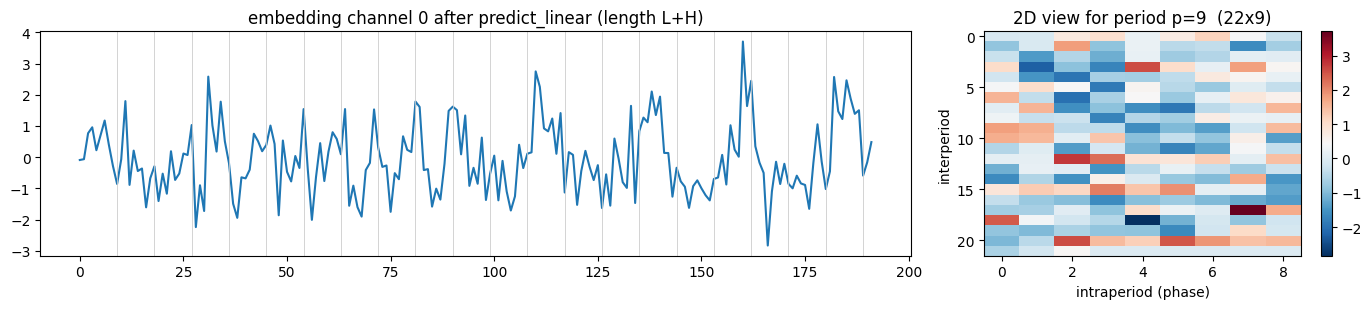

In [12]:
model.eval()
x, y, xm, ym = next(iter(torch.utils.data.DataLoader(test_ds, batch_size=256)))
with torch.no_grad():
    xx = x.to(device); mu = xx.mean(1, keepdim=True); sd = torch.sqrt(xx.var(1, keepdim=True, unbiased=False) + 1e-5)
    e = model.enc_embedding((xx - mu) / sd, xm.to(device))
    e = model.predict_linear(e.permute(0, 2, 1)).permute(0, 2, 1)
    periods, weights = FFT_for_Period(e, cfg.top_k)
w = F.softmax(weights, 1).mean(0).cpu().numpy()
print("periods :", periods.tolist())
print("mean softmax weight:", np.round(w, 3).tolist())

p = int(periods[0]); T = L + H; rows = math.ceil(T / p)
sig = torch.cat([e[0, :, 0], torch.zeros(rows * p - T, device=e.device)]).reshape(rows, p).cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(e[0, :, 0].cpu().numpy()); ax[0].set_title("embedding channel 0 after predict_linear (length L+H)")
for r in range(1, rows): ax[0].axvline(r * p, color="0.8", lw=0.6)
im = ax[1].imshow(sig, aspect="auto", cmap="RdBu_r"); ax[1].set_title(f"2D view for period p={p}  ({rows}x{p})")
ax[1].set_xlabel("intraperiod (phase)"); ax[1].set_ylabel("interperiod"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## Forecast plot (OT channel)

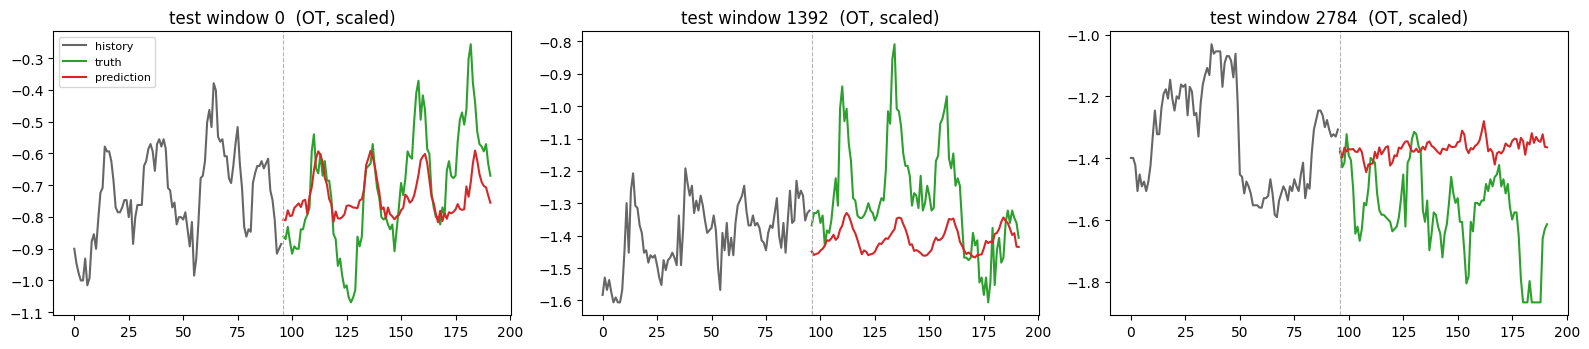

In [13]:
# Forecast plot for the OT channel (oil temperature) on a few test windows
ot = cols.index("OT")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=False)
for ax, k in zip(axes, [0, len(test_ds) // 2, len(test_ds) - 1]):
    x, y, _, _ = test_ds[k]
    ax.plot(np.arange(L), x[:, ot], color="0.4", label="history")
    ax.plot(np.arange(L, L + H), y[:, ot], color="tab:green", label="truth")
    ax.plot(np.arange(L, L + H), test_pred[k, :, ot], color="tab:red", label="prediction")
    ax.axvline(L, color="0.7", ls="--", lw=0.8)
    ax.set_title(f"test window {k}  (OT, scaled)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Results

In [14]:
results = {
    "model": "TimesNet", "paper": "TimesNet: Temporal 2D-Variation Modeling for General Time Series Analysis (arXiv:2210.02186)",
    "venue": "ICLR 2023", "type": "supervised", "lookback": L, "horizon": H,
    "mse": round(float(test_mse), 4), "mae": round(float(test_mae), 4),
    "paper_mse": PAPER_MSE, "paper_mae": PAPER_MAE,
    "params": int(n_params), "train_or_infer_seconds": round(float(train_seconds), 1),
    "notes": ("From-scratch PyTorch re-implementation of TSLib models/TimesNet.py; hyperparameters from TSLib "
              "TimesNet_ETTh1.sh (e_layers=2, d_model=16, d_ff=32, top_k=5, num_kernels=6, lr=1e-4, batch 32, "
              "10 epochs, patience 3, lradj type1, timeF calendar features). Seed 2024, single run. "
              "Test on all 2785 stride-1 windows."),
}
print(json.dumps(results, indent=2))
try:
    with open("results_timesnet_2d_variation.json", "w") as f:
        json.dump(results, f, indent=2)
except Exception as ex:
    print("could not write results file:", ex)

{
  "model": "TimesNet",
  "paper": "TimesNet: Temporal 2D-Variation Modeling for General Time Series Analysis (arXiv:2210.02186)",
  "venue": "ICLR 2023",
  "type": "supervised",
  "lookback": 96,
  "horizon": 96,
  "mse": 0.3986,
  "mae": 0.4183,
  "paper_mse": 0.384,
  "paper_mae": 0.402,
  "params": 605479,
  "train_or_infer_seconds": 55.2,
  "notes": "From-scratch PyTorch re-implementation of TSLib models/TimesNet.py; hyperparameters from TSLib TimesNet_ETTh1.sh (e_layers=2, d_model=16, d_ff=32, top_k=5, num_kernels=6, lr=1e-4, batch 32, 10 epochs, patience 3, lradj type1, timeF calendar features). Seed 2024, single run. Test on all 2785 stride-1 windows."
}


## Using your own data

1. Replace `load_etth1` / `load_etth1_marks` with your own loader returning `train / val / test` arrays of shape `[time, channels]` (scaled with statistics from the training part) and the matching calendar features (or pass `x_mark=None` everywhere: the embedding then uses value + positional terms only).
2. Set `Config.enc_in = c_out = <number of channels>`, and `seq_len` / `pred_len` to your lookback and horizon.
3. `top_k` should not exceed the number of meaningful periods; with hourly data and `seq_len + pred_len ≥ 168`, the daily (24) and weekly (168) cycles become visible to the FFT.
4. For larger datasets (Electricity, Traffic) TSLib uses a bigger `d_model` (e.g. 64–512) and `d_ff`; the code here is unchanged.

```python
cfg.enc_in = cfg.c_out = my_train.shape[1]
cfg.seq_len, cfg.pred_len = 168, 24
model = TimesNet(cfg).to(device)
```